### a) Đọc bộ dữ liệu train, test của MNIST từ Keras

In [1]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from tensorflow.keras.datasets import mnist

# Đọc bộ dữ liệu MNIST từ Keras
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### b) In ra kích thước của tập train, test

In [2]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

print("Kích thước train_images:", train_images.shape)
print("Kích thước train_labels:", train_labels.shape)
print("Kích thước test_images:", test_images.shape)
print("Kích thước test_labels:", test_labels.shape)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Kích thước train_images: (60000, 28, 28)
Kích thước train_labels: (60000,)
Kích thước test_images: (10000, 28, 28)
Kích thước test_labels: (10000,)


### c) Chuẩn hóa các giá trị pixel của ảnh về đoạn [0,1]

In [3]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Chia cho 255.0 để chuẩn hóa pixel về đoạn [0, 1]
train_images = train_images / 255.0
test_images = test_images / 255.0

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


### d) Chia tập train ban đầu thành tập train và tập validation theo tỷ lệ 8:2

In [4]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from sklearn.model_selection import train_test_split

# Chia tập train thành train (80%) và validation (20%)
train_images, validation_images, train_labels, validation_labels = train_test_split(
    train_images, train_labels, test_size=0.2, random_state=42
)

print("Shape của train_images:", train_images.shape)
print("Shape của train_labels:", train_labels.shape)
print("Shape của validation_images:", validation_images.shape)
print("Shape của validation_labels:", validation_labels.shape)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Shape của train_images: (48000, 28, 28)
Shape của train_labels: (48000,)
Shape của validation_images: (12000, 28, 28)
Shape của validation_labels: (12000,)


### e) Xây dựng Neural Network gồm các layers

In [5]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.models import Sequential

# Xây dựng mô hình Sequential
model = Sequential([
    Flatten(
        input_shape=(28, 28)
    ),  # Flatten layer: Làm phẳng ảnh 2D (28x28) thành vector 1D (784 chiều)
    Dense(
        128, activation="relu"
    ),  # Dense layer: 128 neural, hàm kích hoạt Relu, Fully connected
    Dropout(
        0.2
    ),  # Drop out layer: Tắt ngẫu nhiên 20% neuron trong quá trình train để chống overfitting
    Dense(
        10, activation="softmax"
    ),  # Dense layer (Output): 10 class (từ 0 đến 9), hàm kích hoạt Softmax
])

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


### f) Biên dịch mô hình sử dụng optimizer: adam; loss: sparse_categorical_crossentropy; metric: accuracy

In [6]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Biên dịch mô hình
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


### g) Huấn luyện mô hình dựa trên tập train, đánh giá với tập validation; epoch: 5; batch_size: 32

In [7]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Huấn luyện mô hình với fit
history = model.fit(
    train_images,
    train_labels,
    epochs=5,
    batch_size=32,
    validation_data=(validation_images, validation_labels),
    verbose=1,
)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9051 - loss: 0.3277 - val_accuracy: 0.9536 - val_loss: 0.1616
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9544 - loss: 0.1562 - val_accuracy: 0.9657 - val_loss: 0.1127
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9649 - loss: 0.1158 - val_accuracy: 0.9697 - val_loss: 0.1028
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9708 - loss: 0.0957 - val_accuracy: 0.9726 - val_loss: 0.0950
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9751 - loss: 0.0809 - val_accuracy: 0.9745 - val_loss: 0.0801


### h) Vẽ biểu đồ thể hiện accuracy, loss sau mỗi epoch

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


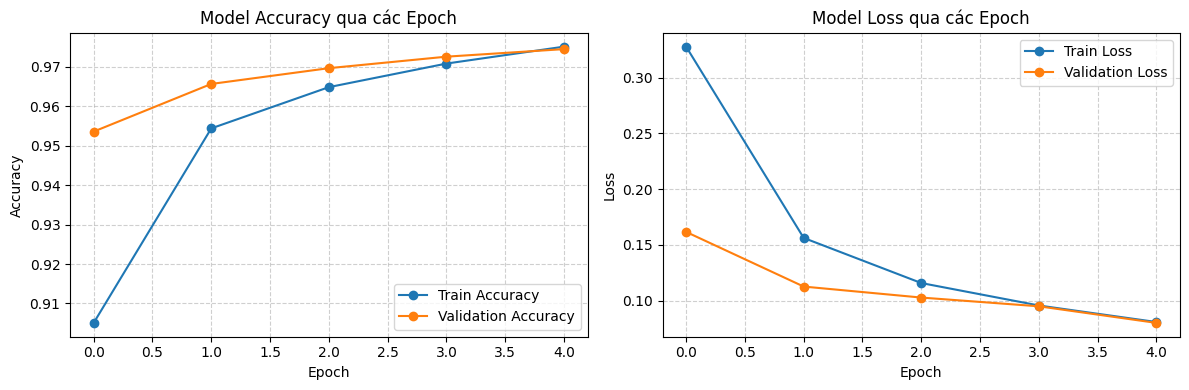

In [8]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

import matplotlib.pyplot as plt

# Vẽ biểu đồ Accuracy
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy", marker="o")
plt.plot(
    history.history["val_accuracy"], label="Validation Accuracy", marker="o"
)
plt.title("Model Accuracy qua các Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Vẽ biểu đồ Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss", marker="o")
plt.plot(history.history["val_loss"], label="Validation Loss", marker="o")
plt.title("Model Loss qua các Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

### i) Dự đoán phân lớp cho tập test

In [9]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

import numpy as np

# Dự đoán xác suất trên tập test
y_pred_prob = model.predict(test_images)
# Chọn class có xác suất lớn nhất bằng numpy argmax
y_pred = np.argmax(y_pred_prob, axis=1)

print("Đã dự đoán xong cho toàn bộ tập test. Số lượng mẫu dự đoán:", len(y_pred))

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Đã dự đoán xong cho toàn bộ tập test. Số lượng mẫu dự đoán: 10000


### j) Tính và in ra Accuracy của mô hình trên tập test

In [10]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from sklearn.metrics import accuracy_score

test_accuracy = accuracy_score(test_labels, y_pred)
print(f"Accuracy của mô hình trên tập test: {test_accuracy * 100:.2f}%")

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Accuracy của mô hình trên tập test: 97.51%


### k) Tính và in ra Precision, Recall, F1-score của từng lớp và trung bình của mô hình trên tập test

In [11]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from sklearn.metrics import classification_report

print("Classification Report trên tập test:")
print(classification_report(test_labels, y_pred))

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Classification Report trên tập test:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.98      0.99      0.99      1135
           2       0.96      0.98      0.97      1032
           3       0.96      0.98      0.97      1010
           4       0.98      0.97      0.98       982
           5       0.98      0.97      0.97       892
           6       0.97      0.98      0.97       958
           7       0.98      0.97      0.97      1028
           8       0.97      0.96      0.96       974
           9       0.98      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.97      0.97     10000
weighted avg       0.98      0.98      0.98     10000



### l) Hiển thị confusion matrix bằng heat map (bản đồ nhiệt)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


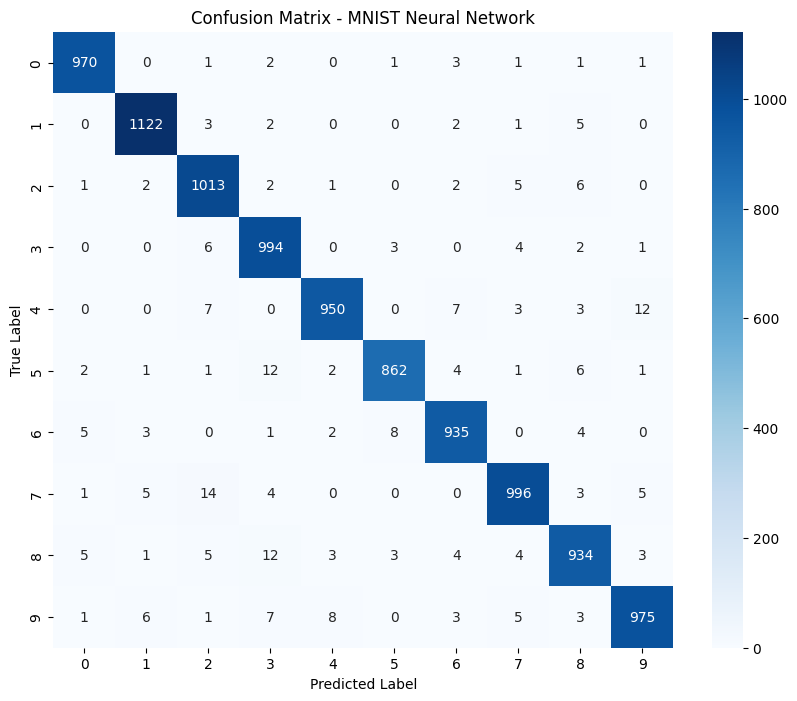

In [12]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(test_labels, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10),
)
plt.title("Confusion Matrix - MNIST Neural Network")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

### m) In ra kết quả phân lớp của 05 ảnh đầu tiên trong tập test

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Ảnh 1 -> Nhãn thực tế: 7 | Nhãn dự đoán: 7
Ảnh 2 -> Nhãn thực tế: 2 | Nhãn dự đoán: 2
Ảnh 3 -> Nhãn thực tế: 1 | Nhãn dự đoán: 1
Ảnh 4 -> Nhãn thực tế: 0 | Nhãn dự đoán: 0
Ảnh 5 -> Nhãn thực tế: 4 | Nhãn dự đoán: 4


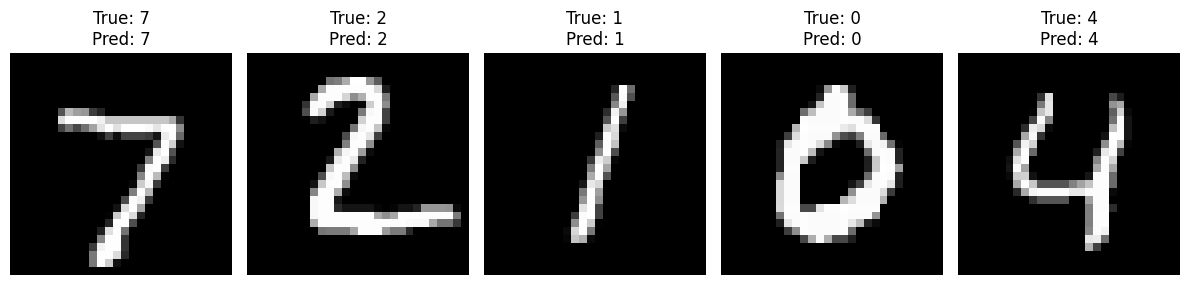

In [13]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

plt.figure(figsize=(12, 3))
for i in range(5):
  # Sử dụng numpy expand_dims (hoặc trực tiếp cắt lát mảng test_images[i]) để lấy ảnh
  img = test_images[i]
  true_label = test_labels[i]
  pred_label = y_pred[i]

  print(
      f"Ảnh {i+1} -> Nhãn thực tế: {true_label} | Nhãn dự đoán:"
      f" {pred_label}"
  )

  plt.subplot(1, 5, i + 1)
  plt.imshow(img, cmap="gray")
  plt.title(f"True: {true_label}\nPred: {pred_label}")
  plt.axis("off")

plt.tight_layout()
plt.show()

### n) In ra 05 kết quả đầu tiên phân lớp sai so với nhãn thực tế trong tập test

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Tổng số mẫu dự đoán sai trên tập test: 249
Hiển thị 05 kết quả đầu tiên phân lớp sai:

Mẫu thứ 1 (index test 115) -> Thực tế: 4 | Dự đoán: 9
Mẫu thứ 2 (index test 151) -> Thực tế: 9 | Dự đoán: 8
Mẫu thứ 3 (index test 247) -> Thực tế: 4 | Dự đoán: 6
Mẫu thứ 4 (index test 321) -> Thực tế: 2 | Dự đoán: 7
Mẫu thứ 5 (index test 340) -> Thực tế: 5 | Dự đoán: 3


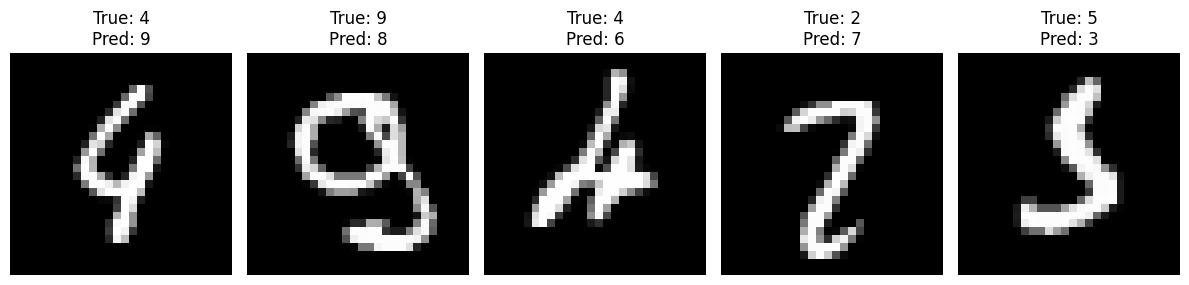

In [14]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Tìm các chỉ số (index) mà dự đoán khác với nhãn thực tế
wrong_indices = np.where(y_pred != test_labels)[0]

print(f"Tổng số mẫu dự đoán sai trên tập test: {len(wrong_indices)}")
print("Hiển thị 05 kết quả đầu tiên phân lớp sai:\n")

plt.figure(figsize=(12, 3))
for i in range(5):
  idx = wrong_indices[i]
  img = test_images[idx]
  true_label = test_labels[idx]
  pred_label = y_pred[idx]

  print(
      f"Mẫu thứ {i+1} (index test {idx}) -> Thực tế: {true_label} | Dự đoán:"
      f" {pred_label}"
  )

  plt.subplot(1, 5, i + 1)
  plt.imshow(img, cmap="gray")
  plt.title(f"True: {true_label}\nPred: {pred_label}")
  plt.axis("off")

plt.tight_layout()
plt.show()